# Interpolation and its assumptions

**Atlas source reading copy · browser-network**

[Course guide](index.ipynb) · [Pinned original](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/0e32b2477ba5c0030985e25f1071d94cddabf130/content/11-interpolation.ipynb)



Browser-only piplite prepares numpy, matplotlib, pandas, xarray and ipywidgets. Calculations use earthlab.py and original synthetic arrays, not observations or real Digital Twin outputs. Optional widget controls need the source frontend; static figures and numerical results provide alternatives. Real DestinE accounts, Polytope/Data Lake services, GRIB/netCDF decoding and HPC remain explicit source/native continuations. No credentials or service requests are required for these defaults.

**Provenance:** `content/11-interpolation.ipynb` at `0e32b2477ba5c0030985e25f1071d94cddabf130`; original SHA-256 `c986a941f0db53741230c165710f5088359d45598fc6bfce7336297dfd0ede90`. Original code MIT; original prose, generated numerical data and cleared artwork CC BY 4.0, with attribution and Atlas adaptation notice. Official DestinE references/datasets are linked context, not copied inputs.

**Verification:** imported by static inspection; saved upstream outputs cleared. Runtime compatibility is separate from executed verification. See the course guide for dependencies, excluded assets, aliases and original credits.


![Original abstract globe and synthetic weather streamlines](assets/splash.png)

# Interpolation and its assumptions

**Lesson 11 · Original synthetic data · Independent educational project**

## Objectives

Sample between grid points; distinguish interpolation from new information.

[Previous](10-wind.ipynb) · [Notebook source](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/content/11-interpolation.ipynb) · [Next](12-ensembles.ipynb)

[Open this notebook in JupyterLite](https://jltobias.github.io/JupyterLite-Destination-Earth-Digital-Twin/lab/index.html?path=11-interpolation.ipynb) — public deployment pending until verified. For a local build, open the matching filename from the Lab file browser.

Run every code cell in order. The first run in JupyterLite downloads browser packages; it needs an internet connection. No account or credentials are used. The interactive visual lessons use ipywidgets, and the gallery provides additional live controls.

## Prepare the browser-sized environment

The shared `earthlab.py` helper lives beside every notebook. The same source notebook is used by the book and Lab.

In [1]:
import sys
if sys.platform == "emscripten":
    import piplite
    await piplite.install(["numpy", "matplotlib", "pandas", "xarray", "ipywidgets"])
import numpy as np
import matplotlib.pyplot as plt
import earthlab as lab
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print(lab.PROVENANCE)

Original synthetic teaching data; not observations or DestinE model output


## Worked experiment

Run this original experiment and inspect both its figure and numerical checks.

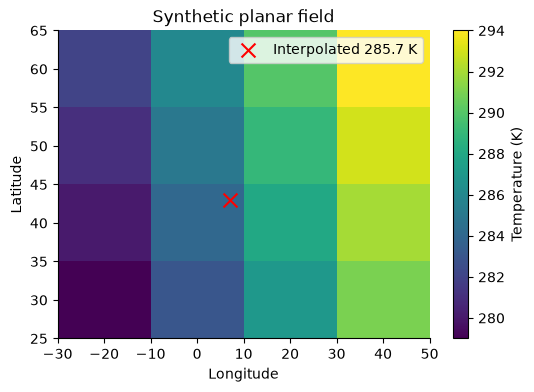

In [2]:
lat = np.array([30., 40., 50., 60.]); lon = np.array([-20., 0., 20., 40.])
x, y = np.meshgrid(lon, lat)
field = 280 + .1*y + .2*x
target_lat, target_lon = 43., 7.
estimated = lab.bilinear(field, lat, lon, target_lat, target_lon)
truth = 280 + .1*target_lat + .2*target_lon
assert np.isclose(estimated, truth)
fig, ax = plt.subplots(figsize=(6, 4))
im = ax.pcolormesh(lon, lat, field, shading="auto")
ax.scatter(target_lon, target_lat, marker="x", s=100, c="red", label=f"Interpolated {estimated:.1f} K")
fig.colorbar(im, ax=ax, label="Temperature (K)")
ax.set(xlabel="Longitude", ylabel="Latitude", title="Synthetic planar field")
ax.legend(); plt.show()

## Exercise

Add a quadratic term to the field and measure interpolation error at the same target. Try an out-of-bounds target and confirm rejection.

Add a code cell with your modification and at least one assertion that would catch an incorrect result. Keep the original experiment as a reference.

## Interpretation and limits

Bilinear interpolation reproduces this plane exactly. It does not preserve every integral, handle the dateline automatically, or recover sub-grid processes.

**Check your reasoning:** identify one result the code establishes and one conclusion the demonstration cannot establish.

## References and provenance

- [Conceptual or software reference](https://docs.scipy.org/doc/scipy/tutorial/interpolate.html) — linked for background; no text, external notebook code or data were copied.
- [Destination Earth initiative source index](https://github.com/destination-earth/DestinE).
- Generated arrays and equations: original project teaching material, CC BY 4.0; helper code: MIT. No authentic DestinE outputs or observational datasets are used.
- The abstract splash was generated for this project. See the repository's [attribution record](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/ATTRIBUTIONS.md).